## 📊 Data Understanding

Tahap **Data Understanding** bertujuan untuk memahami struktur, karakteristik, dan representasi numerik dari data teks yang telah melalui proses preprocessing (pembersihan teks). Teks bersih dikonversi ke beberapa bentuk representasi fitur yang digunakan dalam proses klasifikasi:

| Representasi | Metode |
|---|---|
| Eksistensi Kata | Binary CountVectorizer |
| Frekuensi Kata | CountVectorizer |
| Bobot Kata | TF-IDF |
| Reduksi Dimensi | PCA |

Dataset berisi **200 berita** berlabel `sport` dan `finance`.

---

### 1️⃣ Load Dataset

Membaca file CSV hasil preprocessing (`checkpoint_cleaning.csv`), lalu memilih kolom yang relevan:
- **`id`** – Identifikasi unik tiap dokumen
- **`teks_bersih`** – Teks sudah bersih dari stopword & tanda baca
- **`label`** – Kategori berita (`sport` / `finance`)

Hasilnya disimpan ke `teks_bersih.csv` sebagai titik awal analisis.

In [1]:
import pandas as pd

df = pd.read_csv(
    "data/checkpoint_cleaning.csv"
)

df_all = df[
    ["id", "teks_bersih", "label"]
]

df_all.to_csv(
    "data/teks_bersih.csv",
    index=False,
    encoding="utf-8-sig"
)

### 2️⃣ Informasi Umum Dataset

Menampilkan informasi dasar untuk memastikan data dimuat dengan benar:
- **Jumlah data** – Total baris/dokumen
- **Jumlah atribut** – Total kolom (fitur + label)
- **Nama atribut** – Daftar nama kolom yang tersedia

In [2]:
print(
    "Jumlah data:",
    len(df_all)
)

print(
    "Jumlah atribut:",
    len(df_all.columns)
)

print(
    "Nama atribut:",
    df_all.columns.tolist()
)

Jumlah data: 200
Jumlah atribut: 3
Nama atribut: ['id', 'teks_bersih', 'label']


---

### 3️⃣ Tabel 1 – Representasi Eksistensi Kata (Binary)

Menggunakan `CountVectorizer(binary=True)`. Setiap kata direpresentasikan sebagai:
- **`1`** → kata **ada** dalam dokumen
- **`0`** → kata **tidak ada** dalam dokumen

**Kegunaan:** Cocok untuk algoritma yang hanya memperhatikan *ada-tidaknya* kata, bukan frekuensinya.  
> 💡 Hasil matriks berdimensi `(200 baris × 4896 kolom kata unik)`.

In [3]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer_biner = CountVectorizer(
    binary=True
)

matriks_biner = vectorizer_biner.fit_transform(
    df_all["teks_bersih"]
)

fitur_kata = vectorizer_biner.get_feature_names_out()

df_tabel1 = pd.DataFrame(
    matriks_biner.toarray(),
    columns=fitur_kata
)

# Menambahkan label kategori di kolom paling akhir
df_tabel1["label"] = df_all["label"].values

print("=== TABEL 1 (Eksistensi Kata: 0 atau 1) ===")
display(df_tabel1.tail())

=== TABEL 1 (Eksistensi Kata: 0 atau 1) ===


,aadi,aan,aau,abai,abdi,abdul,abdullah,aberdeen,abraham,absen,...,zaro,zein,zeinatma,zero,zigmars,zona,zoom,zuhair,zulfikar,zulfikri
195,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
196,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
197,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
198,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
199,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### 4️⃣ Dimensi Tabel Binary

Menampilkan ukuran *(shape)* Tabel 1, yaitu `(jumlah_dokumen × jumlah_kata_unik)`.  
Jumlah kolom mencerminkan ukuran **kosakata (vocabulary)** yang diekstrak dari seluruh dokumen.

In [4]:
print("Jumlah baris dan kolom pada Tabel 1:", df_tabel1.shape)

Jumlah baris dan kolom pada Tabel 1: (200, 4896)


---

### 5️⃣ Tabel 2 – Representasi Frekuensi Kata (Term Frequency)

Menggunakan `CountVectorizer()` tanpa `binary=True`, sehingga nilai merepresentasikan **seberapa sering** suatu kata muncul.

| Tabel | Nilai | Contoh |
|---|---|---|
| Tabel 1 (Binary) | 0 atau 1 | Kata "zero" ada → **1** |
| Tabel 2 (Frekuensi) | 0, 1, 2, ... | Kata "zero" muncul 6x → **6** |

**Kegunaan:** Memberikan informasi tambahan tentang tingkat kepentingan relatif suatu kata dalam satu dokumen.

In [5]:
from sklearn.feature_extraction.text import CountVectorizer

# Membuat vectorizer untuk menghitung frekuensi kata
vectorizer_frekuensi = CountVectorizer()

# Transformasi teks_bersih menjadi matriks frekuensi
matriks_frekuensi = vectorizer_frekuensi.fit_transform(
    df_all["teks_bersih"]
)

# Membuat DataFrame (Tabel 2)
df_tabel2 = pd.DataFrame(
    matriks_frekuensi.toarray(),
    columns=vectorizer_frekuensi.get_feature_names_out()
)

# Menambahkan label kategori di kolom paling akhir
df_tabel2["label"] = df_all["label"].values

# Tampilkan hasil Tabel 2
print("=== TABEL 2 (Frekuensi Jumlah Kata) ===")
display(df_tabel2.tail())

=== TABEL 2 (Frekuensi Jumlah Kata) ===


,aadi,aan,aau,abai,abdi,abdul,abdullah,aberdeen,abraham,absen,...,zaro,zein,zeinatma,zero,zigmars,zona,zoom,zuhair,zulfikar,zulfikri
195,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
196,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
197,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
198,0,0,0,0,0,0,0,0,0,0,...,0,0,0,6,0,0,0,0,0,0
199,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### 6️⃣ Simpan Tabel Frekuensi

Menyimpan Tabel 2 ke `tabel_frekuensi.csv` agar dapat digunakan kembali tanpa menjalankan ulang proses vektorisasi.

In [6]:
df_tabel2.to_csv(
    "data/tabel_frekuensi.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Tabel frekuensi berhasil disimpan.")
print("Lokasi: data/tabel_frekuensi.csv")

Tabel frekuensi berhasil disimpan.
Lokasi: data/tabel_frekuensi.csv


---

### 7️⃣ Tabel TF-IDF (Term Frequency – Inverse Document Frequency)

**TF-IDF** adalah teknik pembobotan kata yang mempertimbangkan dua aspek:

| Komponen | Rumus Singkat | Penjelasan |
|---|---|---|
| **TF** | `kemunculan_kata / total_kata_dokumen` | Seberapa sering kata muncul dalam satu dokumen |
| **IDF** | `log(N / df)` | Seberapa *unik* kata di seluruh dokumen |
| **TF-IDF** | `TF × IDF` | Kata sering di satu dok. tapi langka di dok. lain → bobot tinggi |

**Proses:**
1. `CountVectorizer` → matriks frekuensi kata
2. `TfidfTransformer` → ubah frekuensi menjadi bobot TF-IDF


In [7]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfTransformer

# Membaca data
df_all = pd.read_csv(
    "data/teks_bersih.csv"
)

# Vectorizer frekuensi
vectorizer_frekuensi = CountVectorizer()

# Mengubah teks menjadi matriks frekuensi
matriks_frekuensi = vectorizer_frekuensi.fit_transform(
    df_all["teks_bersih"]
)

# Membuat Transformer TF-IDF
transformer_tfidf = TfidfTransformer()

# Mengubah matriks frekuensi menjadi matriks TF-IDF
matriks_tfidf = transformer_tfidf.fit_transform(
    matriks_frekuensi
)

# Membuat DataFrame TF-IDF
df_tfidf = pd.DataFrame(
    matriks_tfidf.toarray(),
    columns=vectorizer_frekuensi.get_feature_names_out()
)

# Menambahkan label kategori
df_tfidf["label"] = df_all["label"].values

# Tampilkan hasil
print("=== TABEL TF-IDF ===")
display(df_tfidf.tail())

=== TABEL TF-IDF ===


,aadi,aan,aau,abai,abdi,abdul,abdullah,aberdeen,abraham,absen,...,zaro,zein,zeinatma,zero,zigmars,zona,zoom,zuhair,zulfikar,zulfikri
195,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
196,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
197,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
198,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.278205,0.0,0.0,0.0,0.0,0.0,0.0
199,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0


### 8️⃣ Visualisasi WordCloud Berdasarkan Bobot TF-IDF

**WordCloud** menampilkan kata-kata secara proporsional berdasarkan **rata-rata bobot TF-IDF** tiap kata.  
Semakin **besar** ukuran kata, semakin tinggi bobotnya (semakin relevan dan khas dalam dataset).

WordCloud dibuat secara terpisah untuk:
- 🏆 **Sport** – kata-kata dominan dari berita olahraga
- 💰 **Finance** – kata-kata dominan dari berita keuangan
- 🌐 **Semua kategori** – gabungan seluruh dokumen

> 💡 Bobot TF-IDF digunakan sebagai nilai *frekuensi* agar ukuran kata mencerminkan kepentingannya, bukan sekadar frekuensi biasa.

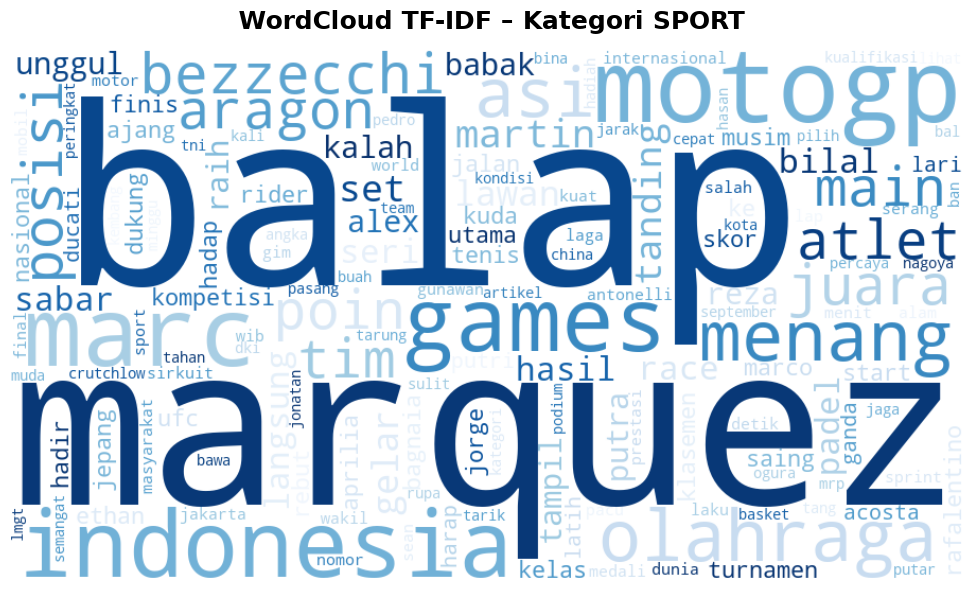

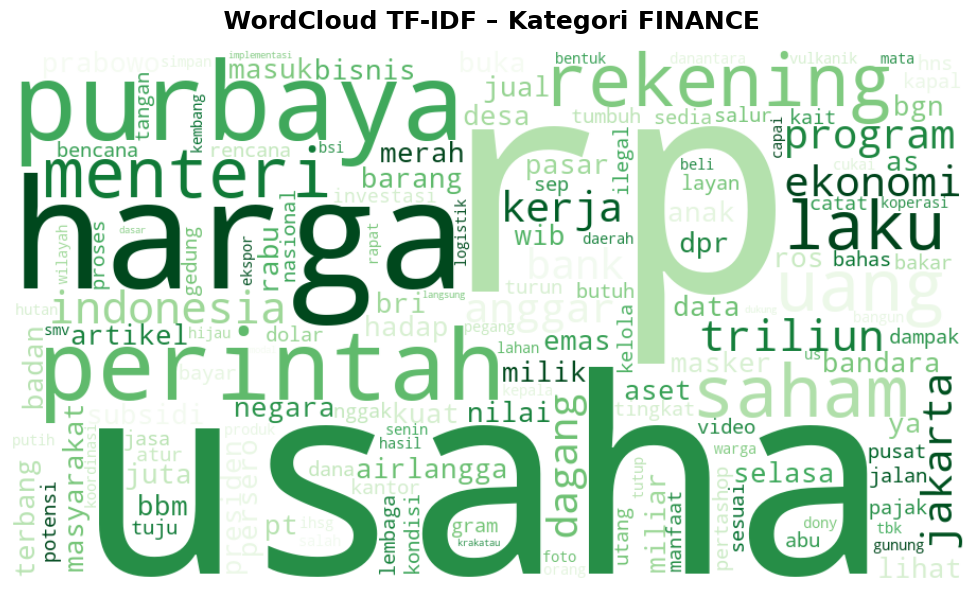

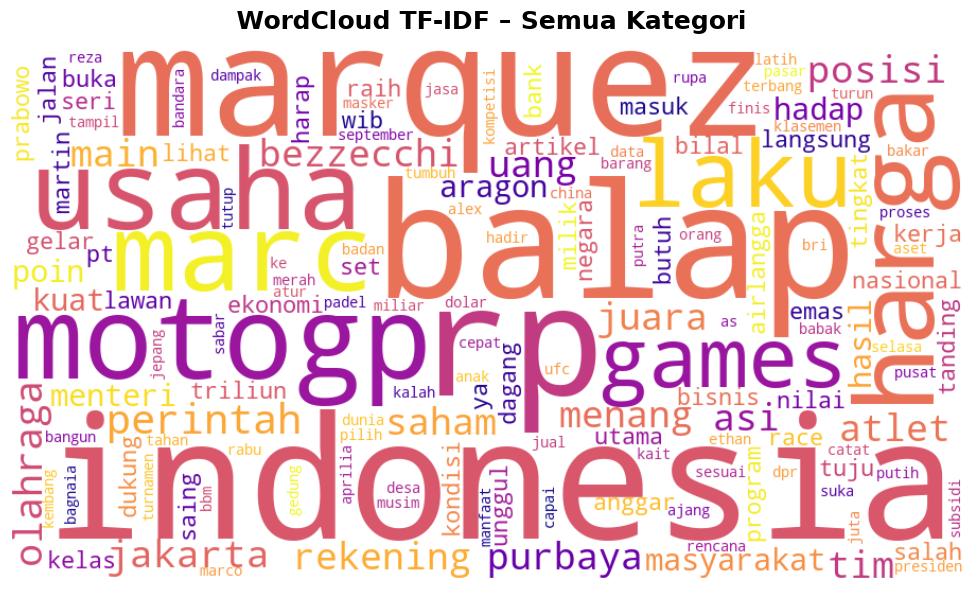

In [16]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# ── Pisahkan kolom fitur (tanpa kolom 'label') ──
df_fitur = df_tfidf.drop(columns=["label"])

# ── Fungsi bantu membuat WordCloud dari dict bobot TF-IDF ──
def buat_wordcloud(bobot_dict, judul, colormap="viridis"):
    wc = WordCloud(
        width=900,
        height=500,
        background_color="white",
        colormap=colormap,
        max_words=150,
        contour_width=1,
        contour_color="steelblue"
    ).generate_from_frequencies(bobot_dict)

    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(judul, fontsize=18, fontweight="bold", pad=15)
    plt.tight_layout()
    plt.show()

# ── 1. WordCloud Kategori SPORT ──
df_sport   = df_tfidf[df_tfidf["label"] == "sport"].drop(columns=["label"])
bobot_sport = {k: v for k, v in df_sport.mean(axis=0).to_dict().items() if v > 0}
buat_wordcloud(bobot_sport, " WordCloud TF-IDF – Kategori SPORT", colormap="Blues")

# ── 2. WordCloud Kategori FINANCE ──
df_finance   = df_tfidf[df_tfidf["label"] == "finance"].drop(columns=["label"])
bobot_finance = {k: v for k, v in df_finance.mean(axis=0).to_dict().items() if v > 0}
buat_wordcloud(bobot_finance, " WordCloud TF-IDF – Kategori FINANCE", colormap="Greens")

# ── 3. WordCloud Semua Kategori ──
bobot_semua = {k: v for k, v in df_fitur.mean(axis=0).to_dict().items() if v > 0}
buat_wordcloud(bobot_semua, " WordCloud TF-IDF – Semua Kategori", colormap="plasma")


### 9️⃣ Simpan Dataset TF-IDF

Menyimpan matriks TF-IDF ke `dataset_tfidf.csv`.  
File ini berisi **4895 kolom fitur** + **1 kolom label** dan menjadi input utama untuk klasifikasi maupun PCA.

In [9]:
# Menyimpan hasil TF-IDF ke CSV
df_tfidf.to_csv(
    "data/dataset_tfidf.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset TF-IDF berhasil disimpan.")
print("Lokasi: data/dataset_tfidf.csv")

Dataset TF-IDF berhasil disimpan.
Lokasi: data/dataset_tfidf.csv


---

### 🔟 Persiapan Data Sebelum PCA

Membuat salinan dataset TF-IDF (`dataset_sebelum_pca`) sebagai input PCA, agar dataset TF-IDF asli tidak berubah.

In [10]:
dataset_sebelum_pca = df_tfidf.copy()

### 1️⃣1️⃣ Reduksi Dimensi dengan PCA

**PCA (Principal Component Analysis)** mengubah 4895 fitur berdimensi tinggi menjadi **5 komponen utama** yang menangkap variansi terbesar.

**Mengapa perlu PCA?**
- Dataset TF-IDF memiliki **4895 kolom** → dimensi sangat tinggi dan sparse
- PCA memampatkan informasi ke **PC1–PC5**
- Mempercepat pelatihan model dan mengurangi overfitting

> ⚠️ Nilai PC bukan kata, melainkan kombinasi linier dari fitur asli.

In [11]:
import pandas as pd
from sklearn.decomposition import PCA



# Memisahkan fitur TF-IDF dan label
fitur = dataset_sebelum_pca.drop(
    "label",
    axis=1
)

label = dataset_sebelum_pca["label"]

# Inisialisasi PCA
# Mengurangi jumlah fitur menjadi 5 komponen utama
pca = PCA(
    n_components=5
)

# Melakukan reduksi dimensi
fitur_pca = pca.fit_transform(
    fitur
)

# Membuat nama kolom PC1, PC2, PC3, PC4, PC5
kolom_pca = [
    f"PC{i+1}"
    for i in range(fitur_pca.shape[1])
]

# Membuat DataFrame setelah PCA
dataset_sesudah_pca = pd.DataFrame(
    fitur_pca,
    columns=kolom_pca
)

# Menambahkan label
dataset_sesudah_pca["label"] = label.values

# Menampilkan hasil
print(
    f"Jumlah kolom sebelum PCA : "
    f"{dataset_sebelum_pca.shape[1]}"
)

print(
    f"Jumlah kolom sesudah PCA : "
    f"{dataset_sesudah_pca.shape[1]}"
)

print("\n=== DATASET SETELAH PCA ===")
display(dataset_sesudah_pca.head())

Jumlah kolom sebelum PCA : 4896
Jumlah kolom sesudah PCA : 6

=== DATASET SETELAH PCA ===


,PC1,PC2,PC3,PC4,PC5,label
0,-0.101406,-0.211456,0.207245,-0.294058,-0.048283,sport
1,0.092019,-0.125078,-0.025312,0.050244,-0.146808,sport
2,-0.030190,-0.121181,0.053690,-0.058693,-0.034794,sport
3,-0.130105,-0.061554,0.251144,-0.286824,0.336576,sport
4,-0.077047,-0.261376,0.242006,-0.176430,0.087838,sport


### 1️⃣2️⃣ Analisis Variance PCA

**Explained Variance Ratio** menunjukkan persentase informasi yang berhasil ditangkap setiap komponen.

> ⚠️ Total ~11.81% berarti 5 komponen PCA menangkap sebagian kecil informasi asli — wajar untuk data TF-IDF berdimensi tinggi dan sangat sparse.  
> Jika diperlukan akurasi lebih tinggi, naikkan nilai `n_components`.

In [12]:
print("=== VARIANCE PCA ===")

for i, variance in enumerate(
    pca.explained_variance_ratio_,
    start=1
):
    print(
        f"PC{i}: {variance * 100:.2f}%"
    )

print(
    f"\nTotal variance yang dipertahankan: "
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

=== VARIANCE PCA ===
PC1: 3.98%
PC2: 2.42%
PC3: 1.92%
PC4: 1.91%
PC5: 1.58%

Total variance yang dipertahankan: 11.81%


### 1️⃣3️⃣ Simpan Dataset PCA

Menyimpan dataset hasil reduksi PCA ke `dataset_pca.csv`.  
Berisi **PC1–PC5** + **label** string (`sport`/`finance`) sebelum dilakukan encoding.

In [13]:
dataset_sesudah_pca.to_csv(
    "data/dataset_pca.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset hasil PCA berhasil disimpan.")
print("Lokasi: data/dataset_pca.csv")

Dataset hasil PCA berhasil disimpan.
Lokasi: data/dataset_pca.csv


### 1️⃣4️⃣ Encoding Label Kategori

Algoritma machine learning membutuhkan label **numerik**. Dilakukan **Label Encoding** manual:

| Label Asli | Label Numerik |
|---|---|
| `sport` | **1** |
| `finance` | **0** |

Setelah encoding, dataset siap untuk pelatihan model klasifikasi.

In [14]:
# One Hot Encoding / Encoding label
dataset_sesudah_pca["label"] = dataset_sesudah_pca["label"].map({
    "sport": 1,
    "finance": 0
})

# Tampilkan hasil
print("=== DATASET PCA SETELAH ENCODING LABEL ===")
display(dataset_sesudah_pca.head())

=== DATASET PCA SETELAH ENCODING LABEL ===


,PC1,PC2,PC3,PC4,PC5,label
0,-0.101406,-0.211456,0.207245,-0.294058,-0.048283,1
1,0.092019,-0.125078,-0.025312,0.050244,-0.146808,1
2,-0.030190,-0.121181,0.053690,-0.058693,-0.034794,1
3,-0.130105,-0.061554,0.251144,-0.286824,0.336576,1
4,-0.077047,-0.261376,0.242006,-0.176430,0.087838,1


### 1️⃣5️⃣ Simpan Dataset PCA Final (Dengan Label Encoding)

Menyimpan dataset PCA akhir dengan label numerik ke `dataset_pca_encoding.csv`.  
File ini menjadi **input final** untuk pelatihan dan evaluasi model klasifikasi.

In [15]:
dataset_sesudah_pca.to_csv(
    "data/dataset_pca_encoding.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset PCA dengan label encoding berhasil disimpan.")

Dataset PCA dengan label encoding berhasil disimpan.
